In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
import sys
import argparse

# Running with the same model pool as LLM-TOPLA.
parser = argparse.ArgumentParser()

parser.add_argument("--device", type=str, default="cuda")
parser.add_argument("--model_names", type=str, default="all")
parser.add_argument("--dataset_type", type=str, default="lang", choices=["lang", "vision"])
parser.add_argument("--task_name", type=str, default="gsm8k", choices=["gsm8k", "mmlu_hf", "bbh", "gpqa", "musr"])

# select agent arguments
parser.add_argument("--alpha", type=float, default=1.0, help="size penalty constant")
parser.add_argument("--select_agent_epoch", type=int, default=15)
parser.add_argument("--select_agent_gamma", type=float, default=0.99)
parser.add_argument("--select_agent_clip_epsilon", type=float, default=0.2)
parser.add_argument("--select_agent_lr", type=float, default=0.001)
parser.add_argument("--focal_div_weight", type=float, default=0.5)
parser.add_argument("--plurality_voting_weight", type=float, default=0.5)
parser.add_argument("--fleiss_kappa_weight", type=float, default=0)
parser.add_argument("--q_stats_weight", type=float, default=0)
parser.add_argument("--corr_coef_weight", type=float, default=0)
parser.add_argument("--binary_disagreement_weight", type=float, default=0)
parser.add_argument("--kappa_stats_weight", type=float, default=0)
parser.add_argument("--binary_entropy_weight", type=float, default=0)

# ensemble agent arguments
parser.add_argument("--ensemble_agent_epoch", type=int, default=15)
parser.add_argument("--ens_agent_gamma", type=float, default=0.5)
parser.add_argument("--ens_agent_clip_epsilon", type=float, default=0.2)
parser.add_argument("--ens_agent_lr", type=float, default=0.001)

# common argumentss for both agents
parser.add_argument("--window_size", type=int, default=500)
parser.add_argument("--max_tolerance", type=int, default=150)
parser.add_argument("--update_freq", type=int, default=100)

# Simulate command-line arguments
if 'ipykernel' in sys.modules:
    sys.argv = ['notebook.py']  # Replace with desired arguments
else:
    sys.argv = ['script.py']

# Parse the arguments
args = parser.parse_args()

In [3]:
from env.ens_env import EnsembleEnv
from focal_agent import PolicyNetwork, MLP, REINFORCE
from data_generator.data_loader import DataCreator

/home/hice1/stekin6/.conda/envs/llamas/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
datacreator = DataCreator(args.task_name, model_names=args.model_names, task_type="lang")
for i, (train_data, test_data, num_models, ds_name) in enumerate(datacreator.load()):
    print()

space_size = (train_data.shape[1] - 1) // num_models
div_metric_weights = np.array([
    args.focal_div_weight,
    args.plurality_voting_weight,
    args.fleiss_kappa_weight,
    args.q_stats_weight,
    args.corr_coef_weight,
    args.binary_disagreement_weight,
    args.kappa_stats_weight,
    args.binary_entropy_weight])
train_env = EnsembleEnv(data=train_data, 
                        num_models=num_models,
                        div_metric_weights=div_metric_weights,
                        device=args.device,
                        window_size=args.window_size, 
                        space_size=space_size,
                        task_name=args.task_name, 
                        alpha=args.alpha)

policy1 = PolicyNetwork(input_dim=train_env.obsv_space_len, 
                        action_dims=np.ones(train_env.ac_space_len).astype(int) * 2)
policy2 = MLP(input_dim=num_models * space_size, 
                hidden_dim=[100, 100], 
                output_dim=space_size)
policy1 = policy1.to(args.device)
policy2 = policy2.to(args.device)




['Llama-2-13b-chat-hf', 'Llama-2-70b-chat-hf', 'Llama-2-7b-chat-hf', 'Mistral-7B-Instruct-v0.2', 'Mixtral-8x7B-Instruct-v0.1', 'gemma-2b', 'gemma-7b', 'phi-2']


Truncating the space size
Truncating the space size



/storage/ice1/1/5/stekin6/rl-focal/focal_agent.py:40: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  torch.nn.init.xavier_uniform(m.weight)


In [5]:
import torch

select_policy_path = "results/checkpoints/gsm8k/exp_30/select_policy_0.pth"
ens_policy_path = "results/checkpoints/gsm8k/exp_30/ens_policy_0.pth"

policy1.load_state_dict(torch.load(select_policy_path))
policy2.load_state_dict(torch.load(ens_policy_path))

/tmp/ipykernel_937610/4119244320.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy1.load_state_dict(torch.load(select_policy_path))
/tmp/ipykernel_937610/4119244320

<All keys matched successfully>

In [6]:
from run import step_policy

agent1 = REINFORCE(policy_network=policy1,
                    lr=args.select_agent_lr,
                    clip_epsilon=args.select_agent_clip_epsilon,
                    gamma=args.select_agent_gamma,
                    aggregate_loss="mean")
agent2 = REINFORCE(policy2,
                    lr=args.ens_agent_lr,
                    clip_epsilon=args.ens_agent_clip_epsilon,
                    gamma=args.ens_agent_gamma,
                    aggregate_loss="sum")

select_args = {
    "agent": agent1,
    "policy": policy1,
    "update": True
}

ens_args = {
    "agent": agent2,
    "policy": policy2,
    "update": True
}

test_env = EnsembleEnv(test_data, num_models, device=args.device, window_size=0, space_size=space_size)
test_reward, marl_errors = step_policy(test_env, select_args, ens_args, num_models, ep_count=0, update_freq=args.update_freq)


100%|██████████| 1240/1240 [01:18<00:00, 15.77it/s]

Episode: 0, Total Acc: 74.58%, Action Counts: [ 132.  292.  113.  116.  981.  133. 1097.  817.], Avg Inf Time: 0.06289s


In [9]:
marl_errors = np.array(marl_errors)

In [10]:
marl_errors.shape

(1240,)

In [11]:
test_data.shape

(1242, 81)

In [12]:
test_data[:, -1]

array([0., 0., 0., ..., 0., 1., 0.])

In [13]:
test_data[2, :10]

array([0.9, 0. , 0. , 0.1, 0. , 0. , 0. , 0. , 0. , 0. ])

In [14]:
novel_data = test_data[:, :-1]
novel_label = test_data[:, -1]
acc = []
base_model_preds = []
for i, novel_arr in enumerate(np.split(novel_data, num_models, axis=1)):
    pred = novel_arr.argmax(axis=1)
    base_model_preds.append(pred)
    model_acc = np.mean(novel_label == pred)
    acc.append(model_acc)
acc = np.array(acc)
# print()
# for i in range(len(acc)):
#     print(f"{datacreator.model_names[i]}: {acc[i] * 100:.2f}")

In [15]:
base_model_preds = np.array(base_model_preds)

In [16]:
base_model_preds

array([[0, 0, 0, ..., 2, 0, 1],
       [0, 0, 0, ..., 0, 0, 3],
       [0, 0, 1, ..., 1, 0, 1],
       ...,
       [0, 2, 0, ..., 3, 0, 5],
       [0, 0, 0, ..., 0, 1, 0],
       [0, 0, 1, ..., 0, 0, 2]])

In [17]:
base_model_preds == novel_label

array([[ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ...,  True, False, False],
       [ True,  True, False, ..., False, False, False],
       ...,
       [ True, False,  True, ..., False, False, False],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True, False, ...,  True, False, False]])

In [23]:
base_model_errors = base_model_preds == novel_label

In [ ]:
base_model_errors[:, 2:]

(8, 1240)

In [27]:
np.save("base_model_errors.npy", base_model_errors)
np.save("marl_focal_errors.npy", marl_errors)

In [29]:
import os
model_names = datacreator._get_model_names(os.path.join("data", "gsm8k"))

In [30]:
model_names

['Llama-2-13b-chat-hf',
 'Llama-2-70b-chat-hf',
 'Llama-2-7b-chat-hf',
 'Mistral-7B-Instruct-v0.2',
 'Mixtral-8x7B-Instruct-v0.1',
 'gemma-2b',
 'gemma-7b',
 'phi-2']

In [31]:
for i in range(len(acc)):
    print(f"{model_names[i]}: {acc[i] * 100:.2f}")

Llama-2-13b-chat-hf: 42.43
Llama-2-70b-chat-hf: 59.90
Llama-2-7b-chat-hf: 24.96
Mistral-7B-Instruct-v0.2: 57.65
Mixtral-8x7B-Instruct-v0.1: 75.36
gemma-2b: 25.28
gemma-7b: 74.15
phi-2: 70.13


In [43]:
selected_model_errors = base_model_errors[[4, 6, 7], 2:].T

In [171]:
ep_corrects, marl_correct = [], []
for i in range(9):
    idx = base_model_errors[:, 2:].T.sum(1) == i    
    print(sum(idx), sum(marl_errors[idx]))
    ep_corrects.append(sum(idx))
    marl_correct.append(sum(marl_errors[idx]))

87 2
105 8
120 49
150 108
155 144
193 186
180 177
136 136
114 114


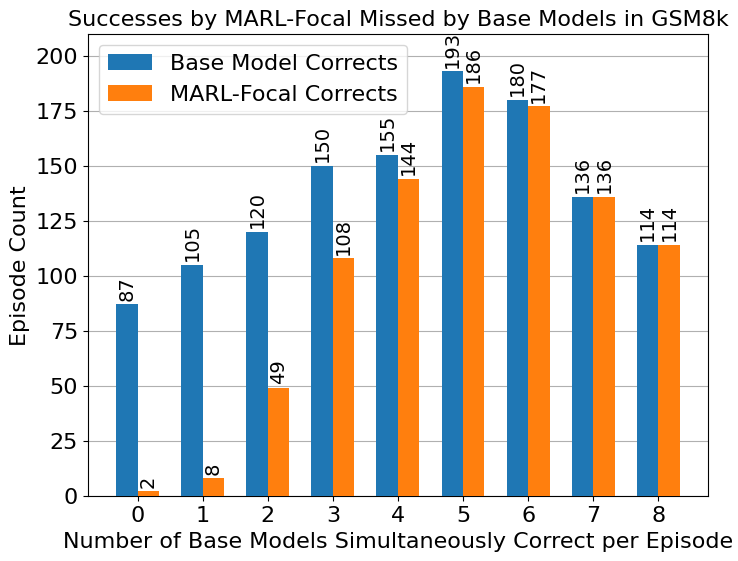

In [173]:

plt.style.use('default')

plt.rcParams.update({
        'font.size': 14,              # General font size
        'axes.titlesize': 16,         # Title font size
        'axes.labelsize': 16,         # Axis label font size
        'xtick.labelsize': 16,        # X-axis tick font size
        'ytick.labelsize': 16,        # Y-axis tick font size
        'legend.fontsize': 16         # Legend font size
    })

x_axis = np.arange(9)
ep_corrects = np.array(ep_corrects)
marl_correct = np.array(marl_correct)

data_dict = {
    "Base Model Corrects": ep_corrects,
    "MARL-Focal Corrects": marl_correct
}


fig, ax = plt.subplots(figsize=(8, 6))
width = 0.33  # the width of the bars
multiplier = 0

# ax.bar(0.25, 76.06, width, label="MARL-Focal", color="r", zorder=3)
colors = ["tab:blue", "tab:green"]
for k, (attribute, measurement) in enumerate(data_dict.items()):
    offset = width * multiplier
    rects = ax.bar(x_axis + offset, measurement, width, label=attribute, zorder=3)
    ax.bar_label(rects, padding=3, rotation=90)
    multiplier += 1
ax.set_xticks(x_axis + width/2, x_axis)
ax.legend(loc='upper left', ncols=1)
ax.set_ylim(0, 210)
# ax.set_yscale('log')
ax.yaxis.grid(zorder=0)
# ax.set_xticks(x_axis)
ax.set_ylabel("Episode Count")
ax.set_xlabel("Number of Base Models Simultaneously Correct per Episode")
ax.set_title("Successes by MARL-Focal Missed by Base Models in GSM8k")
plt.savefig("results/figures/errors_corrected.png", bbox_inches="tight", dpi=150)


In [130]:
groups = [[0], [1], [2], [0, 1], [0, 2], [1, 2], [0, 1, 2]]
groups_str = ["0", "1", "2", "0-1", "0-2", "1-2", "0-1-2"]

ep_corrects, marl_correct = [], []
for i in groups:
    correct_count = len(i)
    idx = (~selected_model_errors)[:, i].sum(1) == correct_count
    ep_corrects.append(idx.sum())
    marl_correct.append(sum(marl_errors[idx]))
    print(idx.sum(), sum(marl_errors[idx]))

306 111
321 94
371 149
151 11
153 14
206 35
112 4


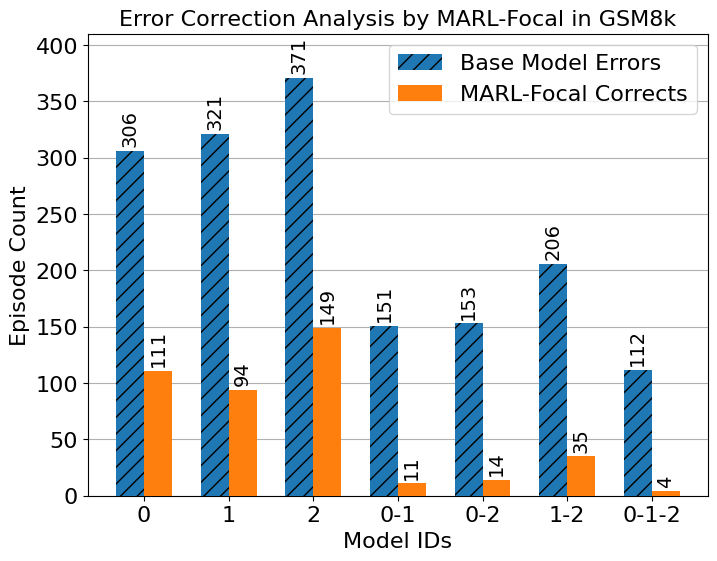

In [170]:
plt.style.use('default')

plt.rcParams.update({
        'font.size': 14,              # General font size
        'axes.titlesize': 16,         # Title font size
        'axes.labelsize': 16,         # Axis label font size
        'xtick.labelsize': 16,        # X-axis tick font size
        'ytick.labelsize': 16,        # Y-axis tick font size
        'legend.fontsize': 16         # Legend font size
    })


x_axis = np.arange(len(groups_str))
ep_corrects = np.array(ep_corrects)
marl_correct = np.array(marl_correct)

data_dict = {
    "Base Model Errors": ep_corrects,
    "MARL-Focal Corrects": marl_correct
}

fig, ax = plt.subplots(figsize=(8, 6))
width = 0.33  # the width of the bars
multiplier = 0

# ax.bar(0.25, 76.06, width, label="MARL-Focal", color="r", zorder=3)
colors = ["salmon", "lightgreen"]
for k, (attribute, measurement) in enumerate(data_dict.items()):
    offset = width * multiplier
    if k == 0:
        rects = ax.bar(x_axis + offset, measurement, width, label=attribute, zorder=3, hatch='//')
    else:
        rects = ax.bar(x_axis + offset, measurement, width, label=attribute, zorder=3)
    ax.bar_label(rects, padding=3, rotation=90)
    multiplier += 1
ax.set_xticks(x_axis + width/2, groups_str)
ax.legend(loc='upper right', ncols=1)
ax.set_ylim(0, 410)
# ax.set_yscale('log')
ax.yaxis.grid(zorder=0)
# ax.set_xticks(x_axis)
ax.set_ylabel("Episode Count")
ax.set_xlabel("Model IDs")
ax.set_title("Error Correction Analysis by MARL-Focal in GSM8k")
plt.savefig("results/figures/error_analysis.png", bbox_inches="tight", dpi=150)

In [122]:
groups_str

['[0]',
 '[1]',
 '[2]',
 '[-0-,- -1-]',
 '[-0-,- -2-]',
 '[-1-,- -2-]',
 '[-0-,- -1-,- -2-]']

In [ ]:

plt.style.use('default')

plt.rcParams.update({
        'font.size': 16,              # General font size
        'axes.titlesize': 16,         # Title font size
        'axes.labelsize': 16,         # Axis label font size
        'xtick.labelsize': 16,        # X-axis tick font size
        'ytick.labelsize': 16,        # Y-axis tick font size
        'legend.fontsize': 16         # Legend font size
    })

x_axis = np.arange(9)
ep_corrects = np.array(ep_corrects)
marl_correct = np.array(marl_correct)

data_dict = {
    "Model Pool": ep_corrects,
    "MARL-Focal": marl_correct
}

width = 0.33  # the width of the bars

fig, ax = plt.subplots(figsize=(8, 6))
rects = ax.bar(x_axis + 0.2, marl_correct/ep_corrects * 100, 0.5, zorder=3, color="seagreen", label="MARL-Focal")
# ax.bar_label(rects, padding=3, rotation=90, fmt='%.2f')

# multiplier = 0

# # ax.bar(0.25, 76.06, width, label="MARL-Focal", color="r", zorder=3)
# colors = ["tab:blue", "tab:green"]
# for k, (attribute, measurement) in enumerate(data_dict.items()):
#     offset = width * multiplier
#     rects = ax.bar(x_axis + offset, measurement, width, label=attribute, zorder=3)
#     ax.bar_label(rects, padding=3, rotation=90)
#     multiplier += 1

# ax.fill_between(np.arange(4, 10), np.repeat(0, 6), np.repeat(240, 6), color='blue', alpha=0.3, label='Majority Reached', zorder=0)
# ax.fill_between(np.arange(-1, 5), np.repeat(0, 6), np.repeat(240, 6), color='green', alpha=0.3, label='No Majority', zorder=0)
ax.plot(np.repeat(4.2, 10), np.linspace(0, 240, 10), "--", color="k", lw=3, zorder=10)
ax.set_xticks(x_axis + width/2, x_axis)
ax.legend(loc='upper left', ncols=1)
ax.set_ylim(0, 105)
ax.set_xlim(0, 9)
# ax.set_yscale('log')
ax.yaxis.grid(zorder=0)
# ax.set_xticks(x_axis)
ax.set_ylabel("Success Rate (%)")
ax.set_xlabel("Number of Models Simultaneously Correct per Episode")
ax.set_title("Successes Rate of MARL-Focal by Concensus")
plt.savefig("results/figures/errors_corrected.png", bbox_inches="tight", dpi=150)


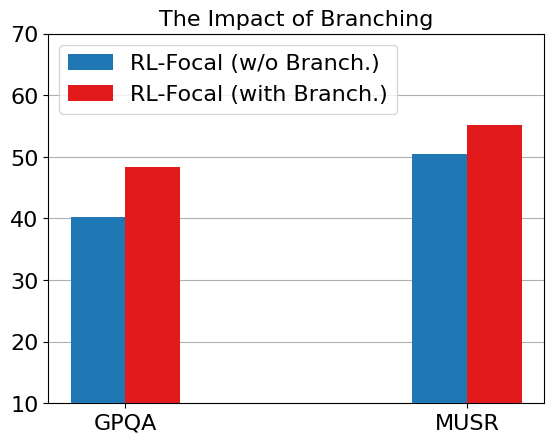

In [32]:
import numpy as np
import matplotlib.pyplot as plt


plt.style.use('default')
# plt.style.use("seaborn-v0_8")


plt.rcParams.update({
        'font.size': 16,              # General font size
        'axes.titlesize': 16,         # Title font size
        'axes.labelsize': 16,         # Axis label font size
        'xtick.labelsize': 16,        # X-axis tick font size
        'ytick.labelsize': 16,        # Y-axis tick font size
        'legend.fontsize': 16         # Legend font size
    })


data_dict = {
    "RL-Focal (w/o Branch.)": [40.23, 50.46],
    "RL-Focal (with Branch.)": [48.28, 55.25]
}

model_names = ["GPQA", "MUSR"]


fig, ax = plt.subplots()

width = 0.08
multiplier = 0
x_axis = np.arange(2)/2


categories = ['A', 'B', 'C', 'D']
values = [1, 5, 3, 8]

# Pick a colormap
cmap = plt.get_cmap("Paired")
colors = cmap(np.array(values))

# colors = ["grey", "tab:green"]
for k, (attribute, measurement) in enumerate(data_dict.items()):
    offset = width * multiplier
    rects = ax.bar(x_axis + offset, measurement, width, label=attribute, zorder=3, color=colors[k])
    # ax.bar_label(rects, padding=3, rotation=90)
    multiplier += 1

ax.set_xticks(x_axis+width/2)
ax.set_xticklabels(model_names)
ax.legend(loc='upper left', ncols=1)
ax.set_ylim(10, 70)
ax.set_title("The Impact of Branching")
# ax.set_xlim(-.1,.75)
ax.yaxis.grid(zorder=0)
plt.savefig("results/figures/branching_impact.png", bbox_inches="tight", dpi=150)
